In [1]:
# Importer les bibliothèques et trouver le dossier des données
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Localiser le dossier data
candidates = [
    Path("data"),
    Path("../data")
]

data_dir = next(
    (p.resolve() for p in candidates if p.exists()),
    None
)

if data_dir is None:
    raise FileNotFoundError("Dossier data introuvable.")

csv_files = list(data_dir.glob("*.csv"))
print("Fichiers trouvés :", [f.name for f in csv_files])

Fichiers trouvés : ['Sample - Superstore.csv', 'superstore_cleaned.csv']


In [2]:
# Charger le fichier CSV et afficher un aperçu
file_path = data_dir / "Sample - Superstore.csv"

df = pd.read_csv(file_path, encoding="cp1252")

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# Vérifier les colonnes, les types, les valeurs manquantes et les doublons
print("Colonnes :")
print(df.columns.tolist())

print("\nTypes de données :")
df.info()

print("\nValeurs manquantes :")
display(df.isna().sum().sort_values(ascending=False))

print("\nLignes entièrement dupliquées :",
      df.duplicated().sum())

Colonnes :
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Types de données :
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


Lignes entièrement dupliquées : 0


In [4]:
# Convertir les dates et les colonnes numériques
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

for col in ["Sales", "Profit", "Quantity", "Discount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dates de commande invalides :",
      df["Order Date"].isna().sum())

print("Valeurs manquantes par colonne :")
display(df.isna().sum())

Dates de commande invalides : 0
Valeurs manquantes par colonne :


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [5]:
# Contrôles de qualité supplémentaires

print("Lignes :", len(df))
print("Doublons complets :", df.duplicated().sum())
print("Valeurs manquantes :", df.isna().sum().sum())

print(
    "Expéditions avant commande :",
    (df["Ship Date"] < df["Order Date"]).sum()
)

print(
    "Quantités nulles ou négatives :",
    (df["Quantity"] <= 0).sum()
)

print(
    "Ventes négatives :",
    (df["Sales"] < 0).sum()
)

print(
    "Remises hors intervalle 0 à 1 :",
    (~df["Discount"].between(0, 1)).sum()
)

Lignes : 9994
Doublons complets : 0
Valeurs manquantes : 0
Expéditions avant commande : 0
Quantités nulles ou négatives : 0
Ventes négatives : 0
Remises hors intervalle 0 à 1 : 0


In [6]:
# Exporter les données préparées dans un nouveau CSV
output_path = data_dir / "superstore_cleaned.csv"

df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("Fichier créé :", output_path)
print("Dimensions :", df.shape)

Fichier créé : C:\Users\Kader\OneDrive\Desktop\Superstore-sales-analysis\data\superstore_cleaned.csv
Dimensions : (9994, 21)


In [7]:
# Calculer les principaux indicateurs de performance
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_units = df["Quantity"].sum()

print(f"Chiffre d'affaires : ${total_sales:,.2f}")
print(f"Bénéfice total : ${total_profit:,.2f}")
print(f"Nombre de commandes : {total_orders:,}")
print(f"Nombre de clients : {total_customers:,}")
print(f"Unités vendues : {total_units:,}")

Chiffre d'affaires : $2,297,200.86
Bénéfice total : $286,397.02
Nombre de commandes : 5,009
Nombre de clients : 793
Unités vendues : 37,873


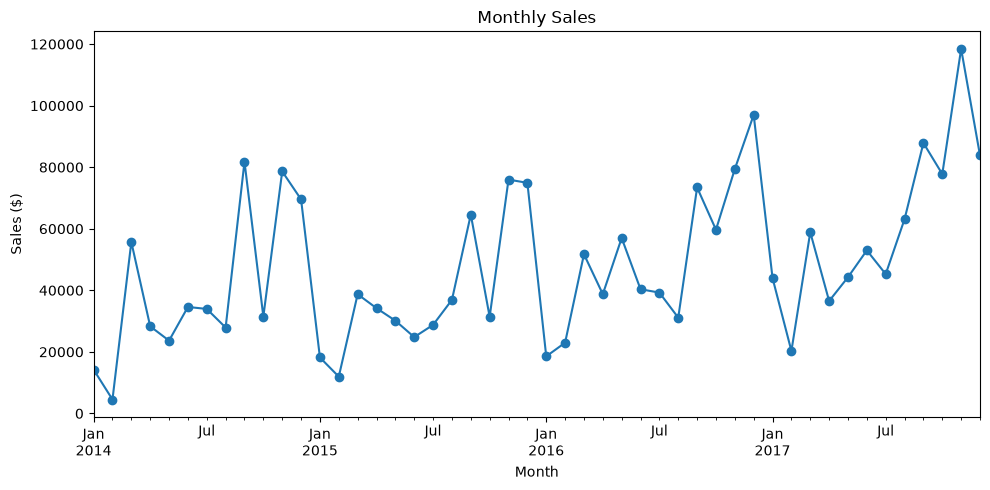

In [8]:
# Regrouper les ventes par mois et afficher leur évolution
monthly_sales = (
    df.dropna(subset=["Order Date"])
      .assign(Month=lambda x:
              x["Order Date"].dt.to_period("M").dt.to_timestamp())
      .groupby("Month")["Sales"]
      .sum()
)

monthly_sales.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

In [9]:
# Créer la base SQLite et y enregistrer les données
import sqlite3

db_path = data_dir.parent / "superstore.db"

conn = sqlite3.connect(db_path)

# SQLite gère mieux les noms simples :
# on renomme les colonnes en minuscules avec underscores.
sql_df = df.copy()

# Convertir les dates au format ISO pour les requêtes SQLite
for col in ["Order Date", "Ship Date"]:
    sql_df[col] = sql_df[col].dt.strftime("%Y-%m-%d")

# Renommer les colonnes pour faciliter les requêtes SQL
sql_df.columns = (
    sql_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

sql_df.to_sql("orders", conn, if_exists="replace", index=False)

print("Base SQLite créée :", db_path.resolve())

Base SQLite créée : C:\Users\Kader\OneDrive\Desktop\Superstore-sales-analysis\superstore.db


In [10]:
# Calculer les ventes et les profits par catégorie avec SQL
query = """
SELECT
    category,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM orders
GROUP BY category
ORDER BY total_sales DESC;
"""

display(pd.read_sql_query(query, conn))

,category,total_sales,total_profit
0,Technology,836154.03,145454.95
1,Furniture,741999.80,18451.27
2,Office Supplies,719047.03,122490.80


In [11]:
# Afficher les tables présentes dans la base SQLite
pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

,name
0,orders


In [12]:
# Fermer la connexion à la base de données
conn.close()